In [73]:
import cv2, math
import numpy as np
import matplotlib.pyplot as plt

(11, 11) float64 0.9999999999999992


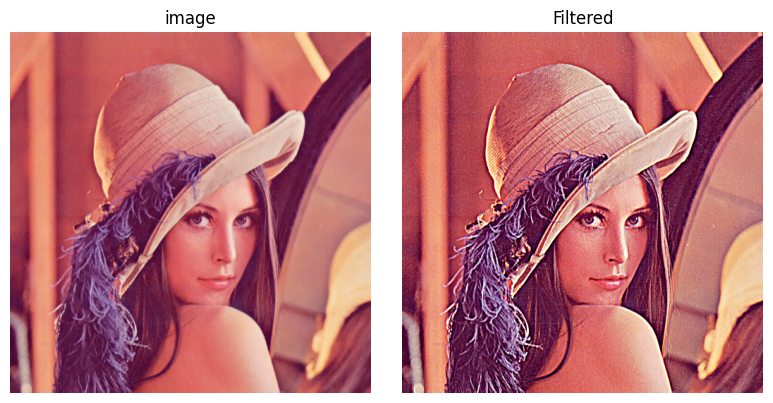

In [74]:
image = cv2.imread('./lena.png')

KSIZE = 11
ALPHA = 2
kernel = cv2.getGaussianKernel(KSIZE, 0)
kernel = -ALPHA * kernel @ kernel.T
kernel[KSIZE//2, KSIZE//2] += 1 + ALPHA
print(kernel.shape, kernel.dtype, kernel.sum())

unsharp = cv2.filter2D(image, -1, kernel)

plt.figure(figsize=(8,4))
plt.subplot(121)
plt.axis('off')
plt.title('image')
plt.imshow(image[:, :, [2, 1, 0]])
plt.subplot(122)
plt.axis('off')
plt.title('Filtered')
plt.imshow(unsharp[:, :, [2, 1, 0]])
plt.tight_layout()
plt.show()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1020.0..1020.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1020.0..1004.0].


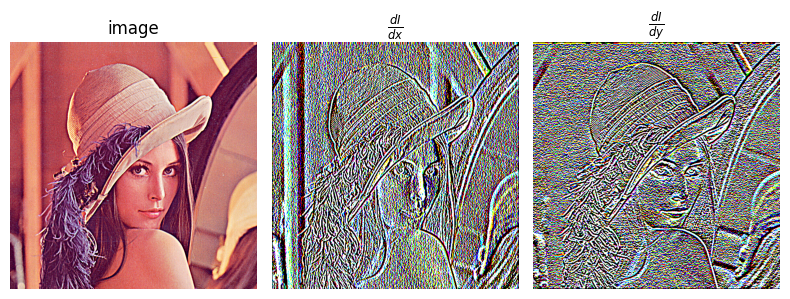

In [75]:
dx = cv2.Sobel(unsharp, cv2.CV_32F, 1, 0)
dy = cv2.Sobel(unsharp, cv2.CV_32F, 0, 1)

plt.figure(figsize=(8,3))
plt.subplot(131)
plt.axis('off')
plt.title('image')
plt.imshow(unsharp[:, :, [2, 1, 0]])
plt.subplot(132)
plt.axis('off')
plt.imshow(dx)
plt.title(r'$\frac{dI}{dx}$')
plt.subplot(133)
plt.axis('off')
plt.title(r'$\frac{dI}{dy}$')
plt.imshow(dy, cmap='gray')
plt.tight_layout()
plt.show()

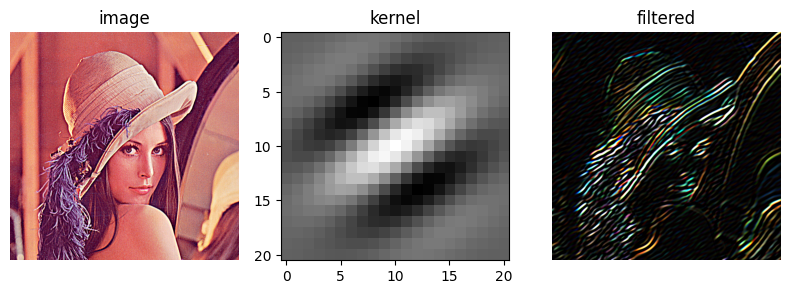

In [77]:
kernel = cv2.getGaborKernel((21, 21), 5, 1, 10, 1, 0, cv2.CV_32F)
kernel /= math.sqrt((kernel * kernel).sum())

filtered = cv2.filter2D(unsharp, -1, kernel)

plt.figure(figsize=(8,3))
plt.subplot(131)
plt.axis('off')
plt.title('image')
plt.imshow(unsharp[:, :, [2, 1, 0]])
plt.subplot(132)
plt.title('kernel')
plt.imshow(kernel, cmap='gray')
plt.subplot(133)
plt.axis('off')
plt.title('filtered')
plt.imshow(filtered[:, :, [2, 1, 0]])
plt.tight_layout()
plt.show()

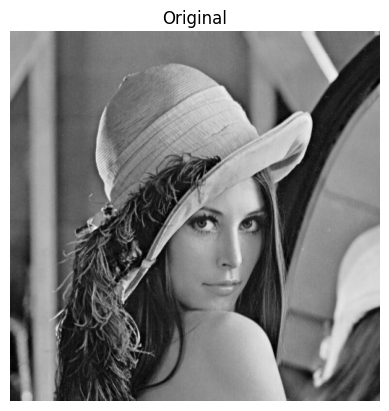

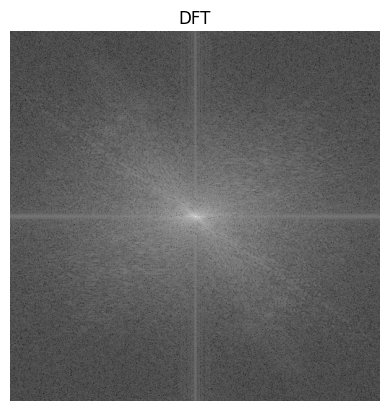

In [60]:
#Frequency-based Filtering
img_gray = cv2.imread('./lena.png', 0).astype(np.float32)

plt.imshow(img_gray, cmap='gray')
plt.title('Original')
plt.axis('off')
plt.show()

dft = np.fft.fft2(img_gray)
dft_shift = np.fft.fftshift(dft)
magnitude = np.log(1 + np.abs(dft_shift))
magnitude = cv2.normalize(magnitude, None, 0, 1, cv2.NORM_MINMAX)
plt.imshow(magnitude, cmap='gray')
plt.title('DFT')
plt.axis('off')
plt.show()

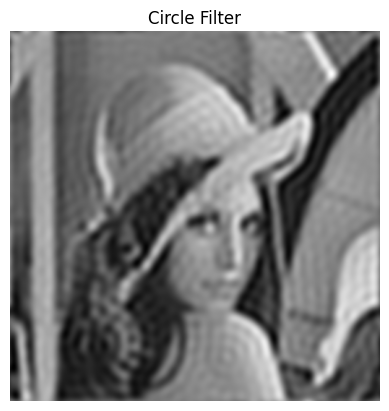

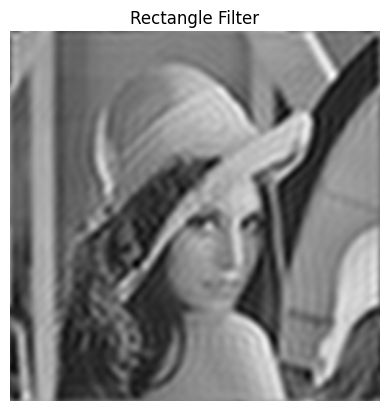

In [61]:
#원 모양과 사각형 모양의 필터링
rows, cols = img_gray.shape[:2]
cy, cx = rows // 2, cols // 2
r = 30

circle_mask = np.zeros((rows, cols), np.uint8)
cv2.circle(circle_mask, (cx, cy), r, 1, -1)

rect_mask = np.zeros((rows, cols), np.uint8)
rect_mask[cy-r:cy+r, cx-r:cx+r] = 1

for mask, title in [(circle_mask, 'Circle Filter'), (rect_mask, 'Rectangle Filter')]:
    filtered = dft_shift * mask
    img_back = np.abs(np.fft.ifft2(np.fft.ifftshift(filtered)))
    img_back = cv2.normalize(img_back, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    plt.imshow(img_back, cmap='gray')
    plt.title(title)
    plt.axis('off')
    plt.show()

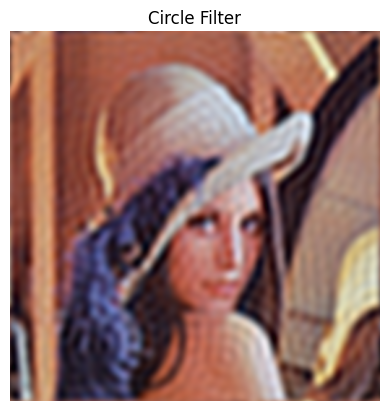

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.1542909e-09..1.0].


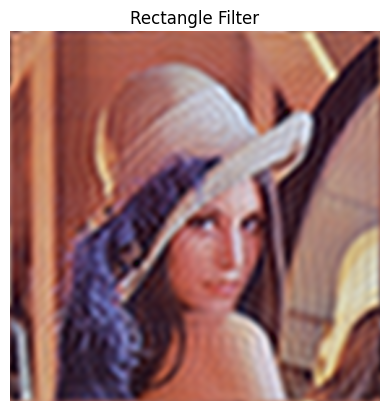

In [62]:
#원 모양과 사각형 모양의 필터링 (컬러)
img_color = cv2.imread('./lena.png').astype(np.float32) / 255
rows, cols = img_color.shape[:2]
cy, cx = rows // 2, cols // 2
r = 30

circle_mask = np.zeros((rows, cols), np.uint8)
cv2.circle(circle_mask, (cx, cy), r, 1, -1)

rect_mask = np.zeros((rows, cols), np.uint8)
rect_mask[cy-r:cy+r, cx-r:cx+r] = 1

for mask, title in [(circle_mask, 'Circle Filter'), (rect_mask, 'Rectangle Filter')]:
    result = np.zeros_like(img_color)
    for i in range(3):
        ch = img_color[:, :, i]
        dft_ch = np.fft.fftshift(np.fft.fft2(ch))
        filtered = dft_ch * mask
        back = np.abs(np.fft.ifft2(np.fft.ifftshift(filtered)))
        result[:, :, i] = cv2.normalize(back, None, 0, 1, cv2.NORM_MINMAX)
    plt.imshow(result[:, :, [2, 1, 0]])
    plt.title(title)
    plt.axis('off')
    plt.show()